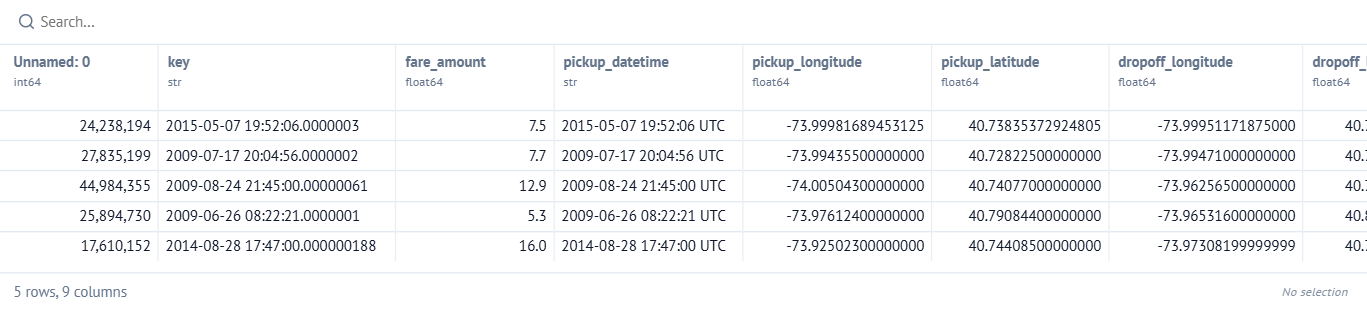

In [ ]:
import pandas as pd
df = pd.read_csv("uber.csv")
df.head()

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


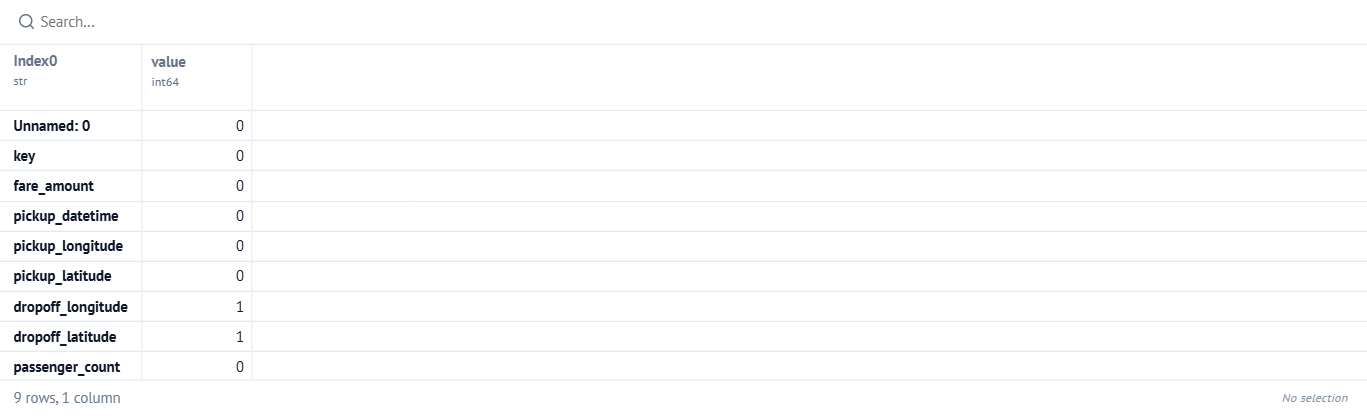

In [ ]:
df.isnull().sum()

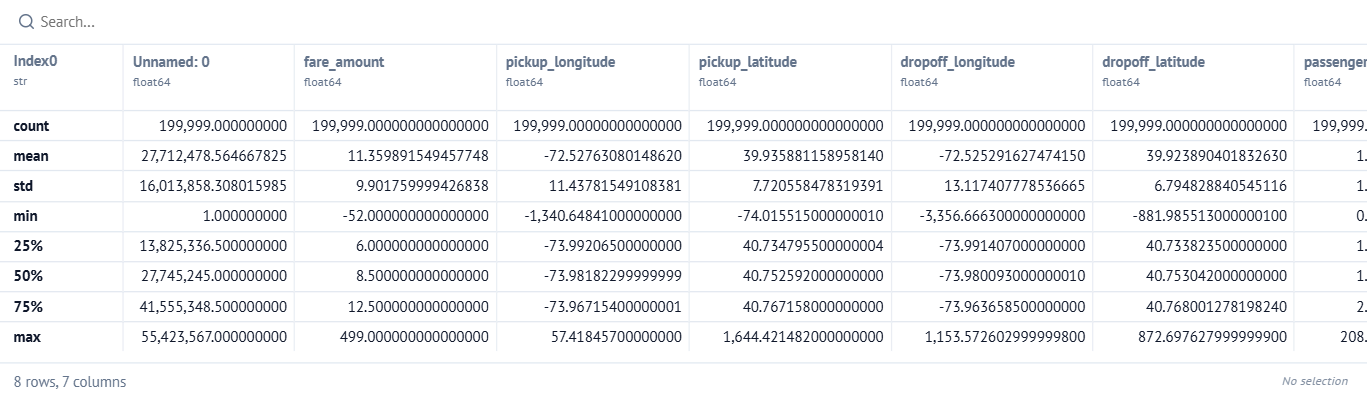

In [ ]:
df_new = df.dropna()
df_new.describe()

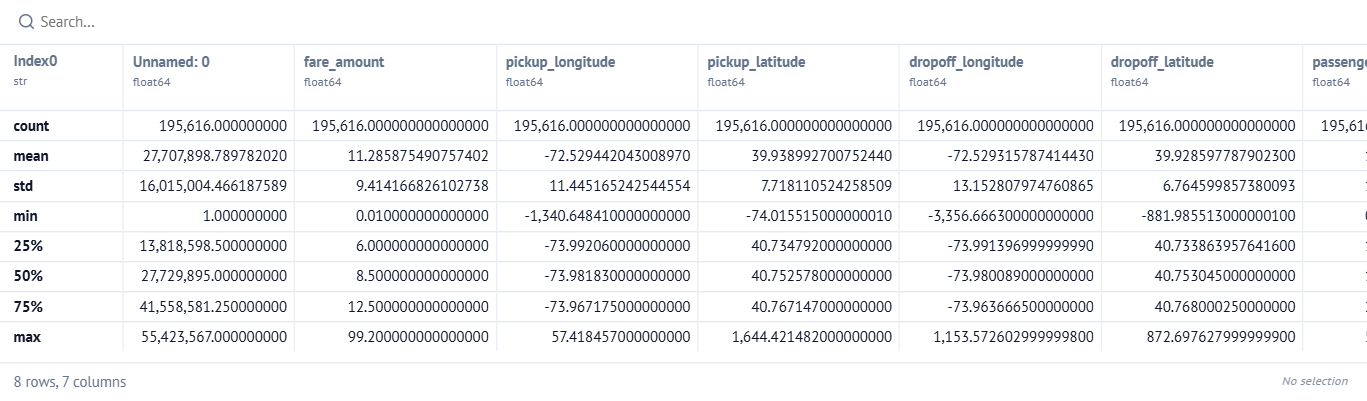

In [ ]:
df_clean = df_new[ (df_new['fare_amount'] > 0) & (df_new['fare_amount'] < 100) & (df_new['passenger_count'] < 6) ]
df_clean.describe()

In [ ]:
df_clean['pickup_datetime'] = pd.to_datetime(df_clean['pickup_datetime'])
df_clean['hour'] = df_clean['pickup_datetime'].dt.hour
df_clean['day_of_week'] = df_clean['pickup_datetime'].dt.dayofweek
df_clean['distance'] = ((df_clean['dropoff_longitude'] - df_clean['pickup_longitude'])**2 + (df_clean['dropoff_latitude'] - df_clean['pickup_latitude'])**2)**0.5

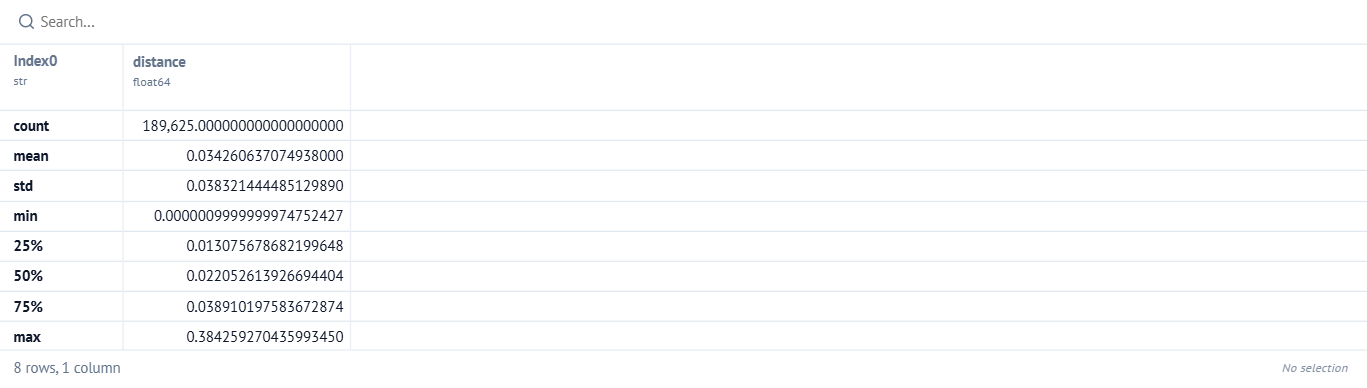

In [ ]:
df_with_km = df_clean[ (df_clean['distance'] > 0) & (df_clean['distance'] < 0.5) ]
df_with_km['distance'].describe()

In [ ]:
Y = df_with_km['fare_amount']
X = df_with_km[ ['passenger_count', 'day_of_week', 'hour', 'distance'] ]  

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, Y_train)
Y_pred = lr.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

MAE = mean_absolute_error(Y_test, Y_pred)
print('the mean absolute error is: ', MAE)

MSE = np.sqrt(mean_squared_error(Y_test, Y_pred))
print('the mean squarred error is: ', MSE)

r2 = r2_score(Y_test, Y_pred)
print('the R-squared error is: ', r2)

the mean absolute error is:  2.2389223079444642
the mean squarred error is:  4.211873780914715
the R-squared error is:  0.7995859561695429


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, Y_train)
Y_pred_rf = rf.predict(X_test)

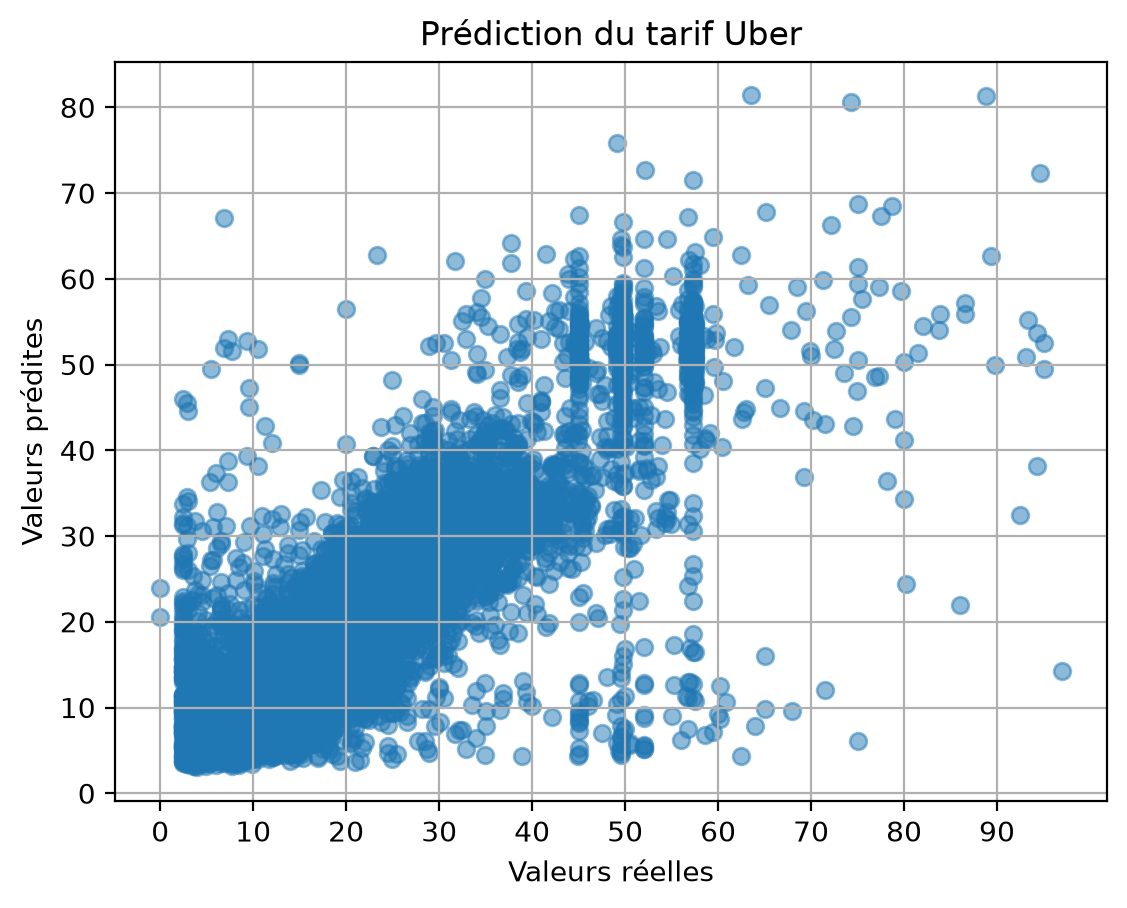

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(Y_test, Y_pred_rf, alpha=0.5)
plt.xlabel('Valeurs réelles')
plt.xticks(np.arange(0,100,10))
plt.ylabel('Valeurs prédites')
plt.title('Prédiction du tarif Uber')
plt.grid()
plt.show()